# 01_3 Synthetic WSI embeddings from the PCA-reduced tile vectors (clusters + hierarchical Gaussians)

**Overview.** This notebook generates synthetic whole-slide-image (WSI) bags from the PCA-reduced UNI2-h tile embeddings saved by `01_2_vectors_to_pca_analysis.ipynb`. For every diagnostic class, the Training tiles are partitioned into *k* clusters (MiniBatchKMeans, Sculley 2010); every cluster is described by a multivariate Gaussian, $x \sim \mathcal{N}(\mu_c, \Sigma_c + \lambda I)$, and a synthetic bag is assembled from a random blend of `N_TEMPLATES_PER_WSI` real Training slides of the same class (Dirichlet weights), whose tile counts and cluster proportions are combined as weighted means. In this way the variation in slide size and in cluster composition of the real data is kept, without using a single global average, without copying a real embedding and without any bag following the composition of one slide. This reduces the link between a synthetic bag and a single real slide; it is not a formal privacy guarantee and no privacy evaluation is made here.

Only the official **Training** slides are used for every estimated quantity: the clusters, the Gaussian parameters, and the templates. The PCA of 01_2 was itself fitted on Training tiles only. Validation and Testing slides are never opened; a mismatch between the slide table, the files and the PCA metadata stops the run. The original PCA files are only read. The notebook does not train a classifier and computes no classification metric; the diagnostics only verify that the generator behaves as specified.

The generation step is behind a small interface (`GeneratorBase`) with two methods. `'gaussian'` samples every tile of a cluster independently from $\mathcal{N}(\mu_c, \Sigma_c + \lambda I)$. `'hier_lowrank'` (the default here) separates two sources of variation in a cluster. The mean of a cluster is shifted in every real slide (stain, scanner, patient), and the shift is shared by all tiles of that slide; the variance of these slide means is the *between-slide* variance $B_c$, estimated per cluster and coordinate from the per-slide cluster means. A synthetic bag draws one offset per cluster, $\delta_c \sim \mathcal{N}(0, s^2 B_c)$ with $s$ = `OFFSET_SCALE`, and shifts all tiles of that cluster by it; the tiles themselves receive only the *within-slide* variance $\Sigma_c - s^2\,\mathrm{diag}(B_c)$, with a diagonal, full, or low-rank-plus-diagonal covariance (`COVARIANCE_TYPE`). A tile-by-tile Gaussian treats the slide shift as independent noise that averages out when a multiple-instance classifier pools the tiles of a bag, so a classifier fitted on such bags never meets a slide-level shift; the hierarchical generator keeps it. With `SHARED_CODEBOOK = True` a single clustering of the tiles of all classes replaces the class-specific one. Synthetic bags are written to `SYNTHETIC_OUTPUT_DIR/<method>/pca_<D>/k_<K>/` with the keys of the PCA files, together with `metadata.json`, `cluster_models.pt` and `labels.csv`; the label sheet of all configurations is `labels/BRACS_synthetic.csv`. No figure or report is exported.

**Options for a leak-free and better-supported generator.** (i) `PER_FOLD` fits the clusters, the statistics, the templates and the generator of every cross-validation fold on the fit slides of that fold only, in the PCA space that notebook 01_2 fitted on the same slides (`cv_fold_<k>/pca_<D>/`); the output goes to `cv_fold_<k>/synthetic/`, so a classifier trained on the bags of a fold (notebook 02_4) never sees a derivative of its held-out slides. (ii) Section 5.1 reports how many Training slides stand behind each cluster, and `MIN_CLUSTER_SLIDES` removes the clusters that fewer slides support (their tiles go to the nearest remaining centre). (iii) `COMPOSITION_MODE = 'lesion_share'` replaces the blending of templates for ADH and DCIS by a model of the share of tiles in lesion clusters (section 6.1), so that bags differ in the extent of the lesion as the real slides do. The default of every option is the earlier behaviour.

```mermaid
flowchart TD
    PCA[("pca_D/UNI2-h/<br/>one .pt file per slide (from 01_2)<br/>PER_FOLD: cv_fold_K/pca_D/")] --> SEL["3. build_sources + select_training<br/>Training slides only, validated<br/>PER_FOLD: fit slides of one fold"]
    SEL --> SAMP["4. sample_class_tiles<br/>slide-balanced, per class"]
    SAMP --> KM["4. fit_class_clusters or fit_shared_clusters<br/>MiniBatchKMeans per class (or one shared codebook)"]
    KM --> STAT["5. collect_class_statistics<br/>one streaming pass: composition, Gaussian sums,<br/>per-slide cluster means"]
    STAT --> SUP["5.1 cluster_support_table<br/>slides per cluster"]
    STAT --> PRUNE["5.2 prune_state<br/>MIN_CLUSTER_SLIDES: drop sparse clusters,<br/>collect the statistics again"]
    PRUNE --> COMP["5. composition_table<br/>real WSI templates (blended in 7)"]
    PRUNE --> LES["6.1 lesion_enrichment + fit_lesion_models<br/>COMPOSITION_MODE lesion_share"]
    PRUNE --> GAUSS["6. GaussianGenerator.fit or HierarchicalGenerator.fit<br/>mean, within / between-slide variance, low-rank factors"]
    COMP --> GEN["7. generate_configuration<br/>make_synthetic_wsi: one offset per cluster and bag"]
    GAUSS --> GEN
    LES --> GEN
    GEN --> DIAG["8. diagnostics<br/>tables and plots, between-slide variance,<br/>real-vs-synthetic AUC"]
    GEN --> SAVE["9. metadata, labels, validation"]
    SAVE --> OUT[("synthetic/method+tag/pca_D/k_K/<br/>SYN_*.pt, metadata.json, labels.csv<br/>PER_FOLD: cv_fold_K/synthetic/")]
    SAVE --> FOLDS["10.1 run_source for the other folds<br/>PER_FOLD"]
    SAVE --> LAB[("labels/BRACS_synthetic.csv")]
```

## 1. Setup

The environment is recorded so the run can be reproduced.

In [1]:
# STEP 1: Standard-library imports and general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('SciPy version:', scipy.__version__)
print('scikit-learn version:', sklearn.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Numpy version: 2.5.4
Pandas version: 3.1.1
SciPy version: 1.18.1
scikit-learn version: 1.9.1
Matplotlib version: 3.11.2


The project's own building blocks are imported.

In [2]:
# STEP 1: Standard-library imports
from pathlib import Path

# STEP 2: Import this project's own building blocks
from utils.pca_analysis import timed
from utils.mil_train import set_seed
from utils.synthetic_gaussian import (between_variance_table, build_generator, cluster_size_table, composition_comparison, cluster_support_table, fidelity_auc,
                                      generation_check, plot_between_variance, plot_cluster_sizes, plot_cluster_support, plot_composition, plot_distribution_stats,
                                      plot_fidelity_auc, plot_pc_scatter, plot_tile_counts, sample_synthetic_tiles, training_overview)
from utils.synthetic_lesion import lesion_share_comparison, lesion_share_table, plot_lesion_fit, proportion_correlation
from utils.synthetic_pipeline import (build_sources, check_params, collect_statistics, fit_clusters, fit_generators, fit_lesion, generate, lesion_bag_auc, prune_state, run_source,
                                      save_state, select_training)

## 2. Constants

Every setting is defined here and any combination of `PCA_DIMENSIONS` and `K_VALUES` can be run without changing the implementation; the dimensions must exist as `pca_<D>/` folders under `PCA_INPUT_DIR`. `GENERATION_METHOD` selects the generator (`'gaussian'` or `'hier_lowrank'`); the output folder is named after it, so the files of the `'gaussian'` method are not touched by a run of `'hier_lowrank'`. Each class is clustered separately on a slide-balanced sample of its Training tiles: every slide gives at most `MAX_TILES_PER_WSI_FIT` tiles and at most `MAX_TILES_PER_CLASS` tiles are used per class (the quotas are reduced equally when the total is larger, so large slides do not dominate). MiniBatchKMeans uses `KMEANS_BATCH_SIZE` and `KMEANS_N_INIT` initialisations; the sample of a class is reused for every *k*.

The Gaussian of a cluster has a diagonal covariance by default (`COVARIANCE_TYPE = 'diag'`: $\mathrm{diag}(\Sigma_c) + \lambda$ with $\lambda$ = `COVARIANCE_REG`); `'full'` uses the Cholesky factor of $\Sigma_c + \lambda I$ and needs $O(kD^2)$ memory per class. A cluster with fewer than `MIN_CLUSTER_TILES` Training tiles has no reliable covariance estimate and uses the pooled within-cluster variance of its class. `N_TEMPLATES_PER_WSI` real Training slides are blended in each bag with Dirichlet weights of concentration `TEMPLATE_CONCENTRATION` (a small concentration lets one template dominate; `1` makes the weights uniform on the simplex; `N_TEMPLATES_PER_WSI = 1` reproduces a single-slide template). `MAX_SYNTHETIC_TILES` caps the size of a synthetic bag (`None` = the weighted mean size of its templates). `N_SYNTHETIC_WSIS_PER_CLASS` bags are generated per class and configuration. `DIAGNOSTIC_CONFIG` is the (dimension, *k*) pair shown in the detailed plots of section 8. `SAVE_SYNTHETIC_EMBEDDINGS` turns the storage on; existing synthetic files are not replaced unless `OVERWRITE` is set. The input spelling `phd_streamembed_features` follows the other notebooks.

**Starting values.** `SHARED_CODEBOOK = True`, `K_VALUES = [100, 150, 250]`, `MIN_SLIDES = 10` and `COVARIANCE_SHRINKAGE = 0.2` are the starting values of the notebook for a generator that rests on better-supported clusters (a shared codebook, fewer clusters, a stricter minimum of slides for the between-slide variance and a covariance shrunk toward the pooled one). They are starting points to tune, not validated settings; section 5.1 shows how well supported the clusters are. `OUTPUT_TAG` is appended to the name of the method folder (`hier_lowrank_shared`), so these sets do not overwrite the earlier ones in `<method>/pca_<D>/k_<K>/`, and `OVERWRITE = False` makes a repeated run stop instead of replacing files. Select the set in notebook 02_4 with `SYNTHETIC_METHOD`.

`PER_FOLD` (default `False`) produces one synthetic set per cross-validation fold (`N_FOLDS`, as in 02_3 and 02_4) from the fit slides of the fold, in the PCA space of the fold (notebook 01_2 with `PER_FOLD = True`; the fit slides are read from the metadata of its PCA folders). The sections below show the fold `DIAGNOSTIC_FOLD`; section 10.1 generates the others with the same code. A fold's seed is `RANDOM_SEED` plus its index. `MIN_CLUSTER_SLIDES` (default `0` = off) is the number of slides (with at least `MIN_SLIDE_TILES` tiles) that a cluster needs; with a shared codebook the slides of all classes are counted together. `COMPOSITION_MODE` is `'blend'` (templates blended, the earlier behaviour) or `'lesion_share'` (ADH and DCIS bags from a lesion-share model, needs `SHARED_CODEBOOK = True`; the folder name gets the suffix `_lesion`). The lesion clusters are those with at least `MIN_LESION_SLIDES` supporting lesion slides, a log2 enrichment of at least `LESION_LOG2_THRESHOLD` in ADH and DCIS slides against the Non-cancer classes `REFERENCE_CLASSES` and a Benjamini-Hochberg-corrected one-sided Mann-Whitney q of at most `LESION_ALPHA`; `N_LESION_MIX_TEMPLATES` real lesion mixes are blended per bag.

The constants of the hierarchical generator are used only with `GENERATION_METHOD = 'hier_lowrank'`. `COVARIANCE_TYPE` is `'diag'`, `'full'` or `'lowrank'`; the low-rank covariance of a cluster is $F F^\top + \Psi$ with `LOWRANK_RANK` factors taken from the leading eigenvectors of the within-slide covariance and a diagonal $\Psi$ that carries the remaining variance, which keeps the per-coordinate variances and avoids the $O(D^3)$ factorisation of the full covariance in every draw. `COVARIANCE_SHRINKAGE` in $[0, 1]$ moves the covariance of a cluster toward the pooled within-cluster covariance of its class (`'full'` and `'lowrank'`). `OFFSET_SCALE` is $s \in [0, 1]$: `0` removes the per-bag offsets (an ablation; with a diagonal covariance the generator equals the `'gaussian'` method) and `1` gives each bag a slide-level shift of the size observed in the real slides. A cluster seen in fewer than `MIN_SLIDES` real slides has an unreliable between-slide variance and is shrunk linearly toward the class-pooled between-slide share of the variance; a slide contributes to the estimate of a cluster only with at least `MIN_SLIDE_TILES` tiles in it. `SHARED_CODEBOOK = True` fits one MiniBatchKMeans on the same number of tiles from every class and uses it for all classes, so a cluster index has the same meaning in every class and the composition of a class is its share of tiles in each shared cluster; the default fits one clustering per class.

In [3]:
# Major variables
PCA_DIMENSIONS = [256]                                             # STEP 1: PCA dimensions to run (folders pca_<D>)
K_VALUES = [100, 150, 250]                                              # STEP 2: Clusters per class (or in the shared codebook); starting values, not validated
GENERATION_METHOD = 'hier_lowrank'                                      # STEP 3: Generator ('gaussian' or 'hier_lowrank'; the output folder is named after it)
N_SYNTHETIC_WSIS_PER_CLASS = 500                                        # STEP 4: Synthetic WSIs per class and configuration
RANDOM_SEED = 42                                                        # STEP 5: Seed of every random choice
PCA_INPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features')           # STEP 6: Holds pca_<D>/<MODEL_NAME>/<slide>.pt (from 01_2)
SYNTHETIC_OUTPUT_DIR = Path('/mnt/Scratch/phd_streamembed_features/synthetic')   # STEP 7: Receives <method>/pca_<D>/k_<K>/
SAVE_SYNTHETIC_EMBEDDINGS = True                                        # STEP 8: Store the synthetic bags (sections 7 and 9)
MODEL_NAME = 'UNI2-h'                                                   # STEP 9: Subfolder with the per-slide files
LABELS_FILE = Path('labels/BRACS.xlsx')                                 # STEP 10: Slide labels, patients and official split
LABELS_SYNTHETIC_FILE = Path('labels/BRACS_synthetic.csv')              # STEP 11: Label sheet of the synthetic WSIs
MAX_TILES_PER_WSI_FIT, MAX_TILES_PER_CLASS = 500, 50_000                # STEP 12: Tiles per slide and per class used to fit the clusters
KMEANS_BATCH_SIZE, KMEANS_N_INIT = 4096, 3                              # STEP 13: MiniBatchKMeans batch size and initialisations
COVARIANCE_TYPE, COVARIANCE_REG = 'lowrank', 1e-3                       # STEP 14: 'diag', 'full' or 'lowrank' ('gaussian': diag or full); lambda added to the variances
MIN_CLUSTER_TILES = 10                                                  # STEP 15: Smaller clusters use the pooled class variance
MAX_SYNTHETIC_TILES = None                                              # STEP 16: Cap on tiles per synthetic WSI (None = blended template size)
N_TEMPLATES_PER_WSI, TEMPLATE_CONCENTRATION = 5, 1.0                    # STEP 17: Real slides blended per bag (1 = one slide); Dirichlet concentration of the weights
DIAGNOSTIC_CONFIG = (PCA_DIMENSIONS[0], K_VALUES[-1])                   # STEP 18: (dimension, k) of the detailed plots
OVERWRITE = True                                                        # STEP 19: Replace existing synthetic outputs (default: refuse)
LOWRANK_RANK = 32                                                       # STEP 20: Factors of the 'lowrank' covariance (hier_lowrank)
OFFSET_SCALE = 1.0                                                      # STEP 21: s in [0, 1]: size of the per-bag offsets of the cluster means (0 = none; hier_lowrank)
MIN_SLIDES, MIN_SLIDE_TILES = 10, 5                                      # STEP 22: Slides below which the between-slide variance of a cluster is shrunk to the pooled value; tiles a slide needs in a cluster to count
COVARIANCE_SHRINKAGE = 0.2                                              # STEP 23: Weight of the pooled covariance in [0, 1] ('full' and 'lowrank'; hier_lowrank)
SHARED_CODEBOOK = True                                                  # STEP 24: One clustering of the tiles of all classes instead of one per class
OUTPUT_TAG = '_shared'                                                  # STEP 25: Appended to the method folder name (hier_lowrank_shared) so earlier sets are not touched; '' = the earlier folder name
PER_FOLD, N_FOLDS, DIAGNOSTIC_FOLD = True, 5, 0                        # STEP 26: One generator per CV fold from its fit slides (01_2 with PER_FOLD first); folds as in 02_3 / 02_4; the fold shown in the diagnostics
MIN_CLUSTER_SLIDES = 0                                                  # STEP 27: Remove clusters seen in fewer slides (0 = off); their tiles go to the nearest remaining centre
COMPOSITION_MODE = 'blend'                                              # STEP 28: 'blend' (templates) or 'lesion_share' (ADH and DCIS from a lesion-share model; needs SHARED_CODEBOOK)
LESION_CLASSES, REFERENCE_CLASSES = ('ADH', 'DCIS'), ('N', 'PB', 'UDH', 'FEA')   # STEP 29: Classes that get lesion-share bags; the Non-cancer classes (benign background and reference of the enrichment)
MIN_LESION_SLIDES, LESION_LOG2_THRESHOLD, LESION_ALPHA = 5, 1.0, 0.05   # STEP 30: Lesion cluster: supporting lesion slides, minimum log2 enrichment, false discovery rate
N_LESION_MIX_TEMPLATES = 3                                              # STEP 31: Real lesion mixes blended per ADH / DCIS bag
set_seed(RANDOM_SEED)
assert DIAGNOSTIC_CONFIG[0] in PCA_DIMENSIONS and DIAGNOSTIC_CONFIG[1] in K_VALUES
PARAMS = dict(method=GENERATION_METHOD, pca_dimensions=PCA_DIMENSIONS, k_values=K_VALUES, n_synthetic_wsis_per_class=N_SYNTHETIC_WSIS_PER_CLASS, seed=RANDOM_SEED, pca_input_dir=PCA_INPUT_DIR,
              synthetic_output_dir=SYNTHETIC_OUTPUT_DIR, save_synthetic_embeddings=SAVE_SYNTHETIC_EMBEDDINGS, model_name=MODEL_NAME, labels_file=LABELS_FILE, labels_synthetic_file=LABELS_SYNTHETIC_FILE,
              max_tiles_per_wsi_fit=MAX_TILES_PER_WSI_FIT, max_tiles_per_class=MAX_TILES_PER_CLASS, kmeans_batch_size=KMEANS_BATCH_SIZE, kmeans_n_init=KMEANS_N_INIT,
              covariance_type=COVARIANCE_TYPE, covariance_reg=COVARIANCE_REG, min_cluster_tiles=MIN_CLUSTER_TILES, max_synthetic_tiles=MAX_SYNTHETIC_TILES,
              n_templates_per_wsi=N_TEMPLATES_PER_WSI, template_concentration=TEMPLATE_CONCENTRATION, lowrank_rank=LOWRANK_RANK, offset_scale=OFFSET_SCALE, min_slides=MIN_SLIDES,
              min_slide_tiles=MIN_SLIDE_TILES, covariance_shrinkage=COVARIANCE_SHRINKAGE, shared_codebook=SHARED_CODEBOOK, output_tag=OUTPUT_TAG, min_cluster_slides=MIN_CLUSTER_SLIDES,
              composition_mode=COMPOSITION_MODE, lesion_classes=LESION_CLASSES, reference_classes=REFERENCE_CLASSES, min_lesion_slides=MIN_LESION_SLIDES,
              lesion_log2_threshold=LESION_LOG2_THRESHOLD, lesion_alpha=LESION_ALPHA, n_lesion_templates=N_LESION_MIX_TEMPLATES)   # the constants above, as the arguments of utils.synthetic_pipeline
check_params(PARAMS)

## 3. Training-data selection

The slide table gives the class, patient and official set of each slide. Only the **Training** slides are selected (with `PER_FOLD`, the fit slides of the fold `DIAGNOSTIC_FOLD`, read from the metadata of its PCA folders, take the place of the official Training slides). For every dimension, each Training slide must have a file with the expected number of columns, finite values, the label of the table and the stored set `Training`; the `fit_slides` recorded by 01_2 must be Training slides too. Any violation raises an error instead of silently using more slides. The table reports the Training slides, patients and tiles per class.

In [4]:
# STEP 1: The data source (the official Training slides, or the fit slides of one fold) and its slide table
sources = build_sources(PARAMS, PER_FOLD, N_FOLDS)
SOURCE = sources[DIAGNOSTIC_FOLD] if PER_FOLD else sources[0]
table = SOURCE['table']

# STEP 2: Validate the Training files of every dimension (memory-mapped, no tile is loaded)
with timed('training-data selection'):
    state = select_training(SOURCE, PARAMS)
training, classes, train = state['training'], state['classes'], state['train']

# STEP 3: Training WSIs and tiles per class
print('Source:', SOURCE['name'])
display(training_overview(train, classes))

[training-data selection] 0.2 s
Source: fold 0


,label,wsis,patients,tiles,median_tiles,min_tiles,max_tiles
0,N,18,12,111063,2896.0,441,27997
1,PB,85,45,1099006,11531.0,337,28956
2,UDH,39,25,379512,8101.0,632,26957
3,FEA,26,17,353364,11468.0,1813,30962
4,ADH,25,14,253087,10608.0,1972,16827
5,DCIS,29,17,327894,10024.0,2083,26726
6,IC,71,37,679565,8645.0,875,26885


## 4. Class-specific MiniBatchKMeans

For each dimension and class, a slide-balanced sample of Training tiles is drawn once and a MiniBatchKMeans is fitted for every *k* (classes are never combined). A seed is derived from the global seed, the dimension, *k* and the class, so each fit is reproducible and independent of the order of the loops. If a class sample has fewer than *k* tiles, *k* is reduced for that class and recorded. With `SHARED_CODEBOOK` the samples of all classes are instead pooled with the same number of tiles per class and one MiniBatchKMeans is fitted per dimension and *k*; the same model is then used for every class. A small random subsample of the real tiles of each class, with the slide of every tile, is kept for the diagnostics of section 8.

In [5]:
# STEP 1: Sample once per (dimension, class); fit one MiniBatchKMeans per k (per class, or one shared codebook per k)
state = fit_clusters(state, PARAMS)
clusters, real_diag, real_groups = state['clusters'], state['real_diag'], state['real_groups']
print({key: {c: m.n_clusters for c, m in per.items()} for key, per in list(clusters.items())[:1]})

[fold 0 D=256 N: sample] 0.1 s
[fold 0 D=256 PB: sample] 0.8 s
[fold 0 D=256 UDH: sample] 0.3 s
[fold 0 D=256 FEA: sample] 0.2 s
[fold 0 D=256 ADH: sample] 0.2 s
[fold 0 D=256 DCIS: sample] 0.2 s
[fold 0 D=256 IC: sample] 0.6 s
[fold 0 D=256: shared codebook k=[100, 150, 250]] 3.4 s
{(256, 100): {'N': 100, 'PB': 100, 'UDH': 100, 'FEA': 100, 'ADH': 100, 'DCIS': 100, 'IC': 100}}


## 5. WSI cluster composition and Gaussian statistics

Every Training slide is read once and its tiles are assigned to the nearest centre of its class. This gives, per slide, the total number of tiles, the tiles per cluster and the normalised cluster proportions, which are the **templates** of the generator. The same pass accumulates per cluster the count, sum and sum of squares (and cross-products for a full covariance) in float64, so the Gaussian parameters use *all* Training tiles of the class, not only the clustering sample. The pass also stores, for every slide and cluster, the mean of the tiles of that slide in the cluster (`slide_mean`, with the tile counts); the hierarchical generator estimates the between-slide variance from them. The mean is $\mu_c = \bar{x}_c$ and the covariance is the unbiased sample covariance $\Sigma_c$.

In [6]:
# STEP 1: One streaming pass per (dimension, k, class): composition and sums (every Training tile must be assigned)
state = collect_statistics(state, PARAMS)
stats, compositions = state['stats'], state['compositions']

# STEP 2: Cluster sizes of every configuration
sizes = {key: {c: s['n'] for c, s in per.items()} for key, per in stats.items()}
display(compositions[DIAGNOSTIC_CONFIG][classes[-1]].head())

[fold 0 D=256 k=100: composition and statistics] 7.0 s
[fold 0 D=256 k=150: composition and statistics] 7.7 s
[fold 0 D=256 k=250: composition and statistics] 8.9 s


,slide,n_tiles,prop_0,prop_1,prop_2,prop_3,prop_4,prop_5,prop_6,prop_7,...,prop_240,prop_241,prop_242,prop_243,prop_244,prop_245,prop_246,prop_247,prop_248,prop_249
0,BRACS_283,14499,0.000000,0.000069,0.000000,0.178288,0.046969,0.000000,0.000000,0.000069,...,0.000000,0.000000,0.000069,0.0,0.0,0.0,0.001655,0.000000,0.000069,0.0
1,BRACS_288,8847,0.000000,0.000000,0.000565,0.006895,0.007799,0.009156,0.000565,0.000000,...,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.030293,0.000565,0.0
2,BRACS_291,8570,0.019137,0.011319,0.001400,0.004317,0.021937,0.000000,0.002100,0.000000,...,0.000117,0.000000,0.000000,0.0,0.0,0.0,0.000817,0.000583,0.010152,0.0
3,BRACS_297,19807,0.006109,0.008835,0.000000,0.000000,0.033725,0.000000,0.000000,0.000000,...,0.000505,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.000101,0.0
4,BRACS_298,15475,0.039225,0.001809,0.003748,0.000000,0.007496,0.002779,0.000905,0.000129,...,0.000129,0.000129,0.000065,0.0,0.0,0.0,0.000000,0.000065,0.000323,0.0


### 5.1 Support of the clusters

For every class and *k* the table gives how many Training slides stand behind each cluster (a slide supports a cluster with at least `MIN_SLIDE_TILES` tiles in it): the median and minimum number of slides per cluster, the share of clusters and of tiles in clusters seen in fewer than five slides, and the largest share of a cluster's tiles that comes from one slide. A cluster that one or two slides define is close to a copy of them: its synthetic tiles reproduce those slides, which weakens both the generalisation of a classifier trained on the bags and the separation of the bags from the source slides, and the cross-validation score of such a set is inflated when the slide is in a held-out fold. The threshold of five slides is a descriptive choice, not a standard. The figure shows, for each class, the cumulative share of tiles by the number of supporting slides; a curve that rises early marks a class with much of its mass in poorly supported clusters. The classes differ in the number of Training slides (with a shared codebook the clusters are the same regions in every class), so the number of slides is bounded by the size of the class. The diagnostic only reads the statistics of section 5.

,pca_dim,k,label,slides,clusters,median_slides,min_slides,share_clusters_few,share_tiles_few,max_single_slide_share,mean_single_slide_share
0,256,100,N,18,91,5.0,0,0.484,0.492,1.000,0.651
1,256,100,PB,85,98,30.0,0,0.051,0.000,1.000,0.234
2,256,100,UDH,39,97,15.0,0,0.113,0.027,1.000,0.410
3,256,100,FEA,26,96,12.0,0,0.260,0.171,1.000,0.411
4,256,100,ADH,25,100,9.0,0,0.240,0.022,1.000,0.357
5,256,100,DCIS,29,99,12.0,0,0.152,0.053,1.000,0.449
6,256,100,IC,71,100,24.5,0,0.060,0.001,0.969,0.253
7,256,150,N,18,133,3.0,0,0.586,0.552,1.000,0.701
8,256,150,PB,85,145,25.0,0,0.076,0.000,1.000,0.257
9,256,150,UDH,39,140,11.5,0,0.157,0.074,0.999,0.431


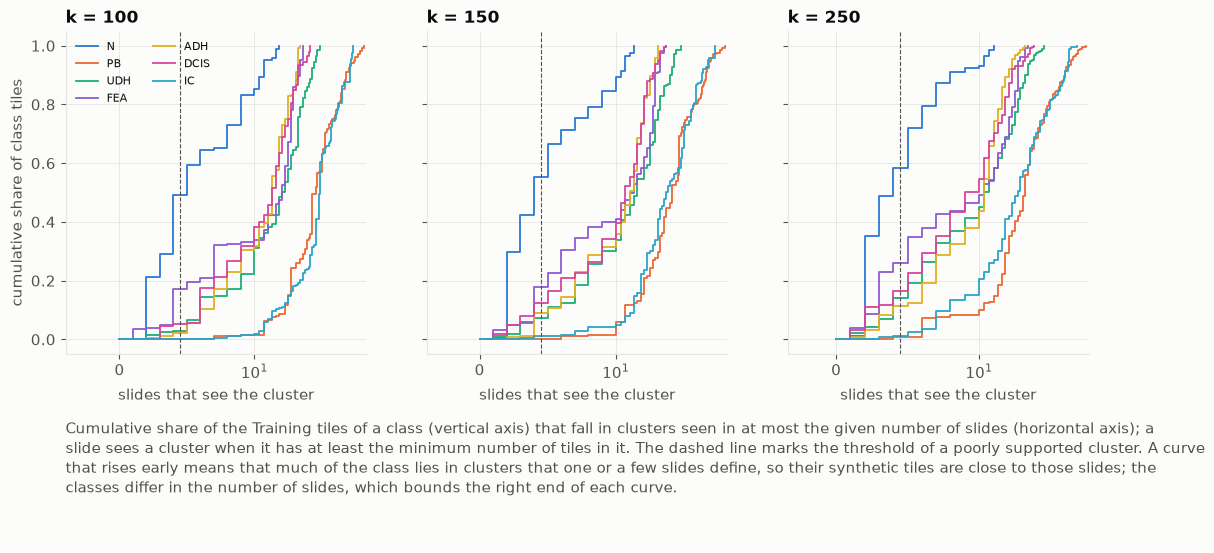

In [7]:
# STEP 1: Slides behind the clusters, per class and k
support = cluster_support_table(stats, classes, MIN_SLIDE_TILES)
display(support[support['pca_dim'] == DIAGNOSTIC_CONFIG[0]].round(3))

# STEP 2: Cumulative tile share by supporting slides
_ = plot_cluster_support(stats, DIAGNOSTIC_CONFIG[0], classes, MIN_SLIDE_TILES)

### 5.2 Clusters seen in few slides

With `MIN_CLUSTER_SLIDES > 0` the clusters that fewer slides support (counted from the per-slide tile counts of the pass above; with a shared codebook over the slides of all classes) are removed: their centres are dropped, so that their tiles are assigned to the nearest remaining centre, and the statistics are collected again with the remaining centres in one more streaming pass. The pass is not repeated, so the reassigned tiles can leave another cluster below the threshold; the support table is shown again for the new clusters. At least one cluster is always kept. The removed clusters, with their slides, tiles and the old index of every kept cluster, are written to `metadata.json`; the folder name keeps the nominal *k* and `effective_k` records the number of clusters that remain. With `MIN_CLUSTER_SLIDES = 0` nothing is changed.

In [8]:
# STEP 1: Remove the sparse clusters and collect the statistics again (nothing happens with MIN_CLUSTER_SLIDES = 0)
state = prune_state(state, PARAMS)
clusters, stats, compositions = state['clusters'], state['stats'], state['compositions']
sizes = {key: {c: s['n'] for c, s in per.items()} for key, per in stats.items()}

# STEP 2: What was removed, and the support of the clusters that remain
if MIN_CLUSTER_SLIDES > 0:
    display(pd.DataFrame([{'pca_dim': d, 'k': k, 'group': g, 'clusters_before': v['n_before'], 'clusters_after': v['n_after'], 'removed_tiles': sum(v['tiles'])}
                          for (d, k), info in state['pruned'].items() for g, v in info.items()]))
    support = cluster_support_table(stats, classes, MIN_SLIDE_TILES)
    display(support[support['pca_dim'] == DIAGNOSTIC_CONFIG[0]].round(3))
else:
    print('MIN_CLUSTER_SLIDES = 0: no cluster is removed.')

MIN_CLUSTER_SLIDES = 0: no cluster is removed.


## 6. Gaussian parameter estimation

For each class and cluster the generator stores $\mu_c$ and either the variances or the Cholesky factor of $\Sigma_c + \lambda I$. With a diagonal covariance no $D \times D$ matrix is formed. Clusters below `MIN_CLUSTER_TILES` use the pooled within-cluster variance of their class; if a Cholesky factorisation fails, jitter is added until it succeeds. The table lists the fallback clusters and the range of the per-coordinate standard deviation.

The hierarchical generator splits the variance $T_c$ of a cluster into a between-slide part $B_c$ and a within-slide part. $B_c$ is the variance of the slide means of the cluster, weighted by the number of tiles of each slide and restricted to slides with at least `MIN_SLIDE_TILES` tiles in the cluster. A slide mean computed from few tiles also contains sampling noise, whose contribution to the weighted variance is approximately $S\,T_c / N$ for $S$ slides and $N$ tiles; it is subtracted with $T_c$ as an upper bound of the within-slide variance, and the result is floored at zero (a method-of-moments estimate that errs toward too little between-slide variance). For a cluster seen in $S_c <$ `MIN_SLIDES` slides the estimate is combined linearly with the pooled between-slide share of the class, with weight $S_c /$ `MIN_SLIDES` on the cluster's own value. The tiles of a bag receive the variance $\max(T_c - s^2 B_c, 0.01\,T_c)$, so the marginal variance of the generated tiles equals the real one for every offset scale $s$. The additional table column `between_share` is the mean share $s^2 B_c / T_c$ of the variance that is moved into the per-bag offsets.


In [9]:
# STEP 1: Fit one generator per (dimension, k, class); the large accumulators are released afterwards
state = fit_generators(state, PARAMS)
generators, options = state['generators'], state['options']

# STEP 2: Summary
rows = []
for (dim, k), per in generators.items():
    for label, g in per.items():
        sd = np.sqrt(g.var + g.reg)
        rows.append({'pca_dim': dim, 'k': k, 'label': label, 'clusters': len(g.mean), 'fallback_clusters': int(g.small.sum()),
                     'min_sd': sd.min(), 'median_sd': float(np.median(sd)), 'max_sd': sd.max(),
                     'between_share': float((g.offset_var / np.maximum(g.total_var, 1e-30)).mean()) if hasattr(g, 'offset_var') else np.nan})
gauss_summary = pd.DataFrame(rows)
display(gauss_summary[(gauss_summary['pca_dim'] == DIAGNOSTIC_CONFIG[0]) & (gauss_summary['k'] == DIAGNOSTIC_CONFIG[1])].round(3))
print('Clusters using the pooled variance, all configurations:', int(gauss_summary['fallback_clusters'].sum()))

[fold 0: Gaussian parameters] 16.5 s


,pca_dim,k,label,clusters,fallback_clusters,min_sd,median_sd,max_sd,between_share
14,256,250,N,250,59,0.113,0.425,2.227,0.176
15,256,250,PB,250,21,0.169,0.442,2.210,0.150
16,256,250,UDH,250,26,0.090,0.438,2.048,0.129
17,256,250,FEA,250,37,0.105,0.442,2.149,0.118
18,256,250,ADH,250,49,0.149,0.449,2.274,0.113
19,256,250,DCIS,250,25,0.115,0.446,2.269,0.134
20,256,250,IC,250,7,0.159,0.449,2.482,0.157


Clusters using the pooled variance, all configurations: 376


### 6.1 Lesion clusters and the lesion-share model (`COMPOSITION_MODE = 'lesion_share'`)

Blending five real templates gives every synthetic ADH or DCIS bag a lesion share close to the class average, whereas the real slides range from a small focus to a large lesion. With `COMPOSITION_MODE = 'lesion_share'` the composition of these two classes is modelled instead. With the shared codebook a cluster is the same region of the embedding space in every class, so the clusters that mark the lesions can be identified from the slides.

**Lesion clusters.** For every cluster the per-slide share of tiles is compared between the ADH and DCIS slides and the Non-cancer slides (`REFERENCE_CLASSES`), with the slide as the unit. A cluster is a *lesion cluster* when at least `MIN_LESION_SLIDES` lesion slides have `MIN_SLIDE_TILES` tiles in it, the log2 ratio of the mean per-slide shares (with a pseudo-count of 0.1/K) is at least `LESION_LOG2_THRESHOLD` (one: twice as frequent), and a one-sided Mann-Whitney U test of the per-slide shares has a Benjamini-Hochberg-corrected q (Benjamini and Hochberg 1995) of at most `LESION_ALPHA` among the eligible clusters. The thresholds are choices of the analysis, not standards, and the clusters are selected on the same slides that generate the bags, so the enrichment is descriptive. The table lists the lesion clusters of the diagnostic configuration.

**Lesion share and size.** The lesion share $\lambda$ of a real slide is the summed proportion of its tiles in the lesion clusters. A Beta distribution is fitted to the $\lambda$ of each class (maximum likelihood on $(0, 1)$) and a lognormal distribution to its tile counts; the table gives the fitted and empirical moments, the Kolmogorov-Smirnov distances and the correlation of $\lambda$ with the log tile count (the two are drawn independently, so a strong correlation would be a limitation), and the figure compares fit and data. With few slides per class the fit is indicative.

**Generation (section 7).** A bag draws $\lambda$ and the tile count, the proportions inside the lesion clusters (summing to $\lambda$) from a Dirichlet blend of `N_LESION_MIX_TEMPLATES` real lesion mixes of the class, and the proportions of the other clusters (summing to $1-\lambda$) from a Dirichlet blend of Non-cancer slides whose lesion clusters were removed and renormalised; the tiles are then sampled by the generator of the class. The other classes (including IC) keep the blending of templates. Without this mode nothing is computed here.

In [10]:
# STEP 1: Lesion clusters and the lesion-share model of every configuration (COMPOSITION_MODE = 'lesion_share' only)
state = fit_lesion(state, PARAMS)
if COMPOSITION_MODE == 'lesion_share':
    lesion = state['lesion']
    enrichment = lesion[DIAGNOSTIC_CONFIG]['enrichment']
    print(f'Lesion clusters of D={DIAGNOSTIC_CONFIG[0]}, k={DIAGNOSTIC_CONFIG[1]}:', int(enrichment['lesion'].sum()), 'of', len(enrichment))
    display(enrichment[enrichment['lesion']].sort_values('log2_enrichment', ascending=False).round(4))

    # STEP 2: Fitted lesion share and tile count against the real slides
    display(lesion_share_table(lesion[DIAGNOSTIC_CONFIG]['models']).round(3).set_index('label').T)
    _ = plot_lesion_fit(lesion[DIAGNOSTIC_CONFIG]['models'])
else:
    print("COMPOSITION_MODE = 'blend': templates are blended, no lesion model is fitted.")

COMPOSITION_MODE = 'blend': templates are blended, no lesion model is fitted.


## 7. Synthetic WSI generation

For each class, `N_SYNTHETIC_WSIS_PER_CLASS` bags are generated. `N_TEMPLATES_PER_WSI` distinct real Training slides of the class are drawn (different bags may reuse a slide) and combined with Dirichlet weights; the weighted mean of their tile counts (capped by `MAX_SYNTHETIC_TILES`) is split over the clusters with the weighted mean of their proportions (largest-remainder rounding, so the counts sum to the tile count). No template identifier is stored; only the number of templates and the largest weight of a single template are recorded, the generator draws its per-bag state once (for the hierarchical generator one offset per cluster, shared by all tiles of that cluster in the bag), the vectors of each cluster are sampled from its Gaussian in batches, and the tiles are shuffled. With `COMPOSITION_MODE = 'lesion_share'` the bags of the lesion classes are made as described in section 6.1 and their lesion share is written to `lesion_share.csv` in the configuration folder; the method folder then has the suffix `_lesion`. The cluster means of the first 30 bags (100 or more in the lesion-share mode) of each class are kept for the diagnostic of section 8.6. Every bag is validated (shape, NaN, infinity) and re-assigned to the class clusters. When `SAVE_SYNTHETIC_EMBEDDINGS` is set, each bag is written as soon as it is generated to `SYNTHETIC_OUTPUT_DIR/<method>/pca_<D>/k_<K>/`, so the bags are never held in memory together. The identifiers (`SYN_<method>_pca<D>_k<K>_<class>_<i>`) contain no real slide or patient identifier.

In [11]:
# STEP 1: Generate every configuration (and write the bags of the diagnostic source when SAVE_SYNTHETIC_EMBEDDINGS)
out_dir = SOURCE['out_root'] if SAVE_SYNTHETIC_EMBEDDINGS else None
state = generate(state, PARAMS, out_dir, OVERWRITE)
results = state['results']
print(len(results), 'configurations generated')

[fold 0 D=256 k=100: generation] 263.4 s
[fold 0 D=256 k=150: generation] 249.8 s
[fold 0 D=256 k=250: generation] 241.3 s
3 configurations generated


## 8. Diagnostics

The following tables and figures check that the generator works as specified. They are not an evaluation of the synthetic data for a downstream task.

### 8.1 Real Training WSIs and tiles, and generated WSIs

The counts of generated WSIs are compared with the configuration; a difference raises an error.

In [12]:
# STEP 1: Generated WSIs per configuration and class against the request
check = generation_check(results, N_SYNTHETIC_WSIS_PER_CLASS, classes)
display(check.pivot_table(index=['pca_dim', 'k'], columns='label', values='generated')[classes])
print('Requested per class:', N_SYNTHETIC_WSIS_PER_CLASS, '| total generated:', int(check['generated'].sum()),
      '| files written:', int(check['files'].sum()))

label            N     PB    UDH    FEA    ADH   DCIS     IC
pca_dim k                                                   
256     100  500.0  500.0  500.0  500.0  500.0  500.0  500.0
        150  500.0  500.0  500.0  500.0  500.0  500.0  500.0
        250  500.0  500.0  500.0  500.0  500.0  500.0  500.0

Requested per class: 500 | total generated: 10500 | files written: 10500


### 8.2 Cluster sizes

The table gives, for each configuration and class, the smallest, median and largest cluster (Training tiles) and the share of the largest. The figure shows the sorted cluster shares per class, one figure per dimension.

,pca_dim,k,label,clusters,min,median,max,largest_share,empty
0,256,100,N,100,0,450.0,12402,0.112,9
1,256,100,PB,100,0,8240.0,97088,0.088,2
2,256,100,UDH,100,0,2817.5,16308,0.043,3
3,256,100,FEA,100,0,2337.0,40421,0.114,4
4,256,100,ADH,100,1,1652.5,15871,0.063,0
5,256,100,DCIS,100,0,2515.0,16939,0.052,1
6,256,100,IC,100,3,3827.0,50698,0.075,0
7,256,150,N,150,0,248.5,9672,0.087,17
8,256,150,PB,150,0,4478.5,89023,0.081,5
9,256,150,UDH,150,0,1728.0,12137,0.032,10


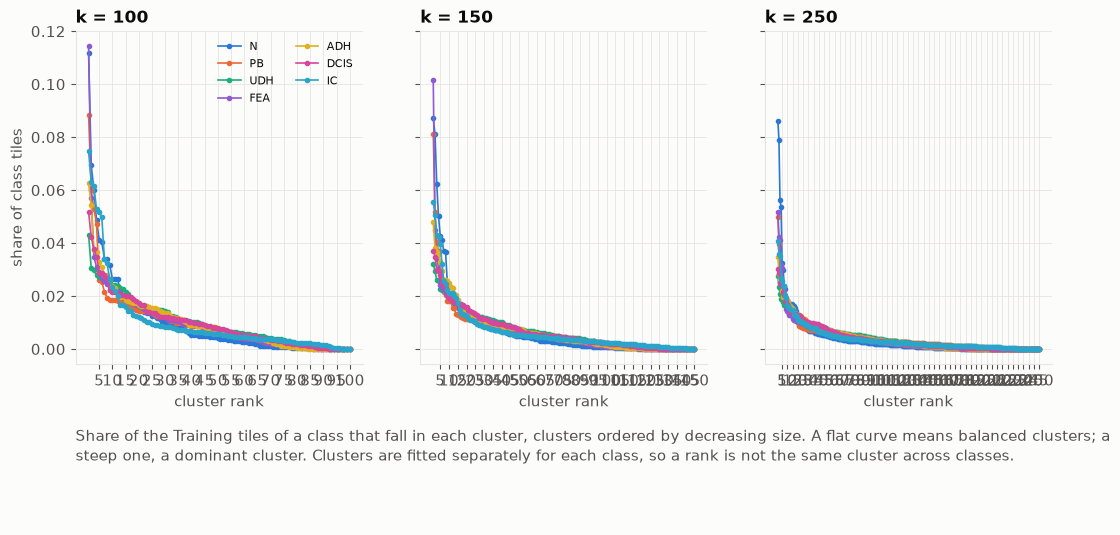

In [13]:
# STEP 1: Cluster-size table of every configuration
size_table = cluster_size_table(sizes)
display(size_table[size_table['pca_dim'] == DIAGNOSTIC_CONFIG[0]].round(3))

# STEP 2: Sorted cluster shares, one figure per dimension
for dim in PCA_DIMENSIONS:
    _ = plot_cluster_sizes(sizes, dim, classes)

### 8.3 Real and synthetic tile counts

The tile counts of the synthetic bags are compared with those of the real Training slides of the same class for the diagnostic configuration. Blending templates preserves the mean size but narrows its spread. The table of the largest weight of a single template shows how far one slide can dominate a bag.

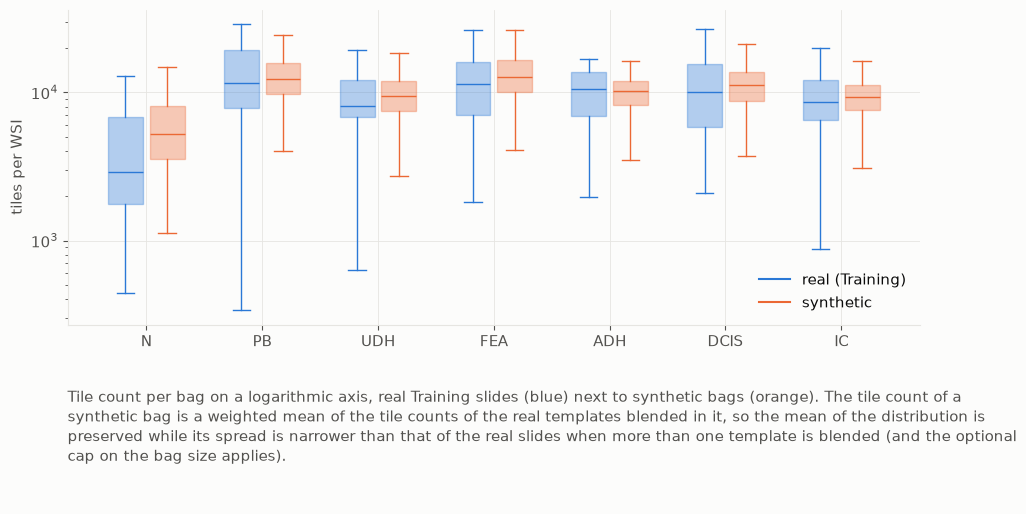

real                                                              \
     count     mean     std     min     25%      50%      75%      max   
N     18.0   6170.0  7299.0   441.0  1752.0   2896.0   6838.0  27997.0   
PB    85.0  12929.0  7412.0   337.0  7860.0  11531.0  19346.0  28956.0   
UDH   39.0   9731.0  6089.0   632.0  6774.0   8101.0  12160.0  26957.0   
FEA   26.0  13591.0  8399.0  1813.0  6996.0  11468.0  16150.0  30962.0   
ADH   25.0  10123.0  4820.0  1972.0  6981.0  10608.0  13763.0  16827.0   
DCIS  29.0  11307.0  6640.0  2083.0  5875.0  10024.0  15583.0  26726.0   
IC    71.0   9571.0  4808.0   875.0  6496.0   8645.0  12140.0  26885.0   

     synthetic                                                               
         count     mean     std     min      25%      50%      75%      max  
N        500.0   6267.0  3833.0  1125.0   3529.0   5233.0   8060.0  24153.0  
PB       500.0  12995.0  4232.0  4014.0   9793.0  12341.0  15833.0  26675.0  
UDH      500.0   9953.0  3494.0  2725.0   7511.0   9386.0  11882.0  22118.0  
FEA      500.0  13484.0  4698.0  4056.0  10000.0  12664.0  16588.0  28845.0  
ADH      500.0  10055.0  2626.0  3500.0   8233.0  10246.0  11939.0  16201.0  
DCIS     500.0  11394.0  3652.0  3718.0   8733.0  11208.0  13823.0  23800.0  
IC       500.0   9464.0  2685.0  2223.0   7666.0   9272.0  11230.0  22028.0

,count,mean,std,min,25%,50%,75%,max
WSI label,,,,,,,,
N,500.0,0.45,0.11,0.21,0.37,0.43,0.51,0.84
PB,500.0,0.45,0.12,0.26,0.36,0.43,0.53,0.85
UDH,500.0,0.47,0.12,0.23,0.38,0.44,0.53,0.90
FEA,500.0,0.45,0.12,0.26,0.36,0.44,0.52,0.91
ADH,500.0,0.46,0.12,0.24,0.37,0.44,0.52,0.88
DCIS,500.0,0.46,0.12,0.21,0.37,0.43,0.53,0.90
IC,500.0,0.45,0.12,0.23,0.37,0.44,0.52,0.91


In [14]:
# STEP 1: Tile counts per class
res = results[DIAGNOSTIC_CONFIG]
_ = plot_tile_counts(train, res['wsis'], classes)
display(pd.concat({'real': train.groupby('label')['n_tiles'].describe(),
                   'synthetic': res['wsis'].groupby('WSI label')['n_tiles'].describe()}, axis=1).reindex(classes).round(0))
display(res['wsis'].groupby('WSI label')['max_template_weight'].describe().reindex(classes).round(2))

### 8.4 Real and synthetic cluster proportions

For the diagnostic configuration, the mean proportion per cluster of the real templates is compared with the synthetic bags (as drawn and after re-assignment). The standard deviation of the proportions over slides (real) and over bags (synthetic) is compared as well. The table gives the mean absolute difference over clusters for every configuration.

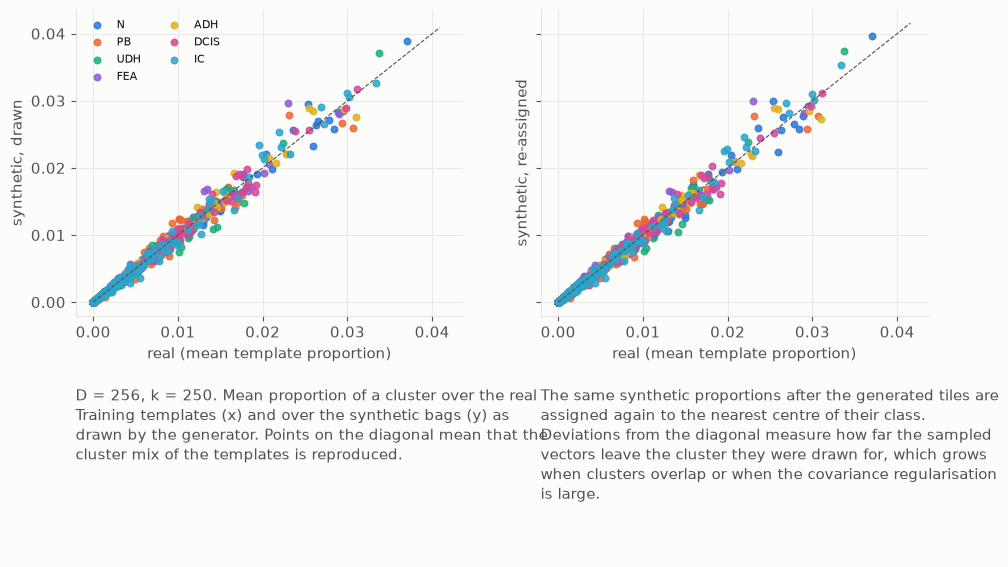

,pca_dim,k,drawn_vs_real,reassigned_vs_real
0,256,100,0.0005,0.0006
1,256,150,0.0004,0.0004
2,256,250,0.0002,0.0003


,real_std,drawn_std
label,,
N,0.0113,0.0060
PB,0.0150,0.0084
UDH,0.0123,0.0069
FEA,0.0105,0.0059
ADH,0.0102,0.0057
DCIS,0.0117,0.0065
IC,0.0152,0.0086


In [15]:
# STEP 1: Detailed comparison of the diagnostic configuration
comparison = composition_comparison(compositions[DIAGNOSTIC_CONFIG], res)
_ = plot_composition(comparison, classes, title=f'D = {DIAGNOSTIC_CONFIG[0]}, k = {DIAGNOSTIC_CONFIG[1]}.')

# STEP 2: Mean absolute difference per configuration
rows = []
for (dim, k), r in results.items():
    cmp_ = composition_comparison(compositions[(dim, k)], r)
    rows.append({'pca_dim': dim, 'k': k, 'drawn_vs_real': (cmp_['drawn'] - cmp_['real']).abs().mean(),
                 'reassigned_vs_real': (cmp_['reassigned'] - cmp_['real']).abs().mean()})
display(pd.DataFrame(rows).round(4))
display(comparison.groupby('label')[['real_std', 'drawn_std']].mean().reindex(classes).round(4))

### 8.5 Embedding statistics of real and synthetic tiles

For each class, a subsample of real Training tiles is compared with synthetic tiles coordinate by coordinate (mean and standard deviation) and by the mean vector norm; the first two principal components of the diagnostic configuration are plotted.

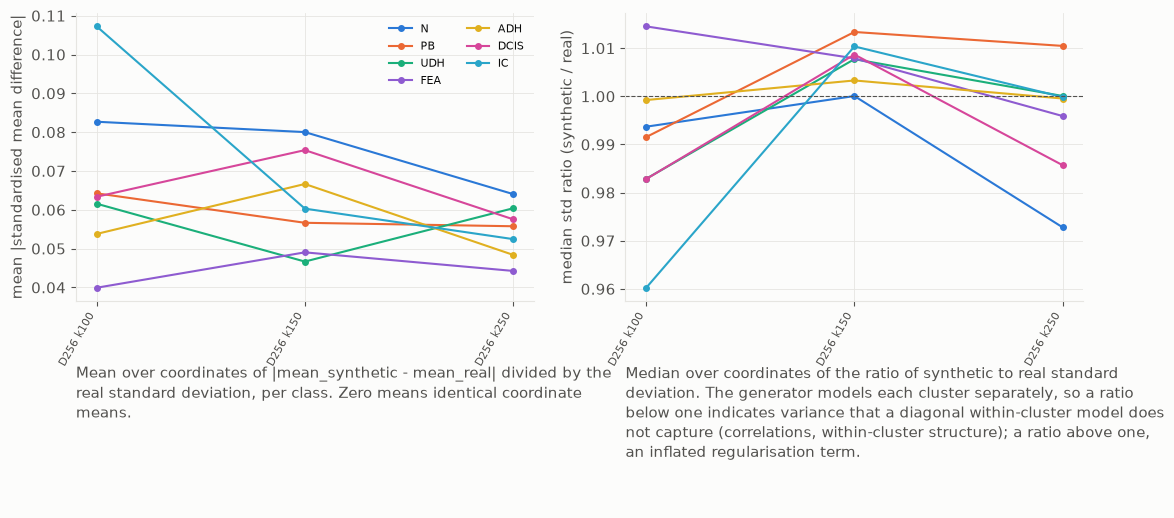

,label,mean_abs_smd,median_std_ratio,norm_real,norm_synthetic,pca_dim,k
14,N,0.064,0.973,12.661,11.967,256,250
15,PB,0.056,1.010,12.892,13.214,256,250
16,UDH,0.060,1.000,12.822,13.030,256,250
17,FEA,0.044,0.996,12.908,13.151,256,250
18,ADH,0.048,1.000,12.965,13.057,256,250
19,DCIS,0.058,0.986,13.009,12.562,256,250
20,IC,0.052,1.000,12.822,13.015,256,250


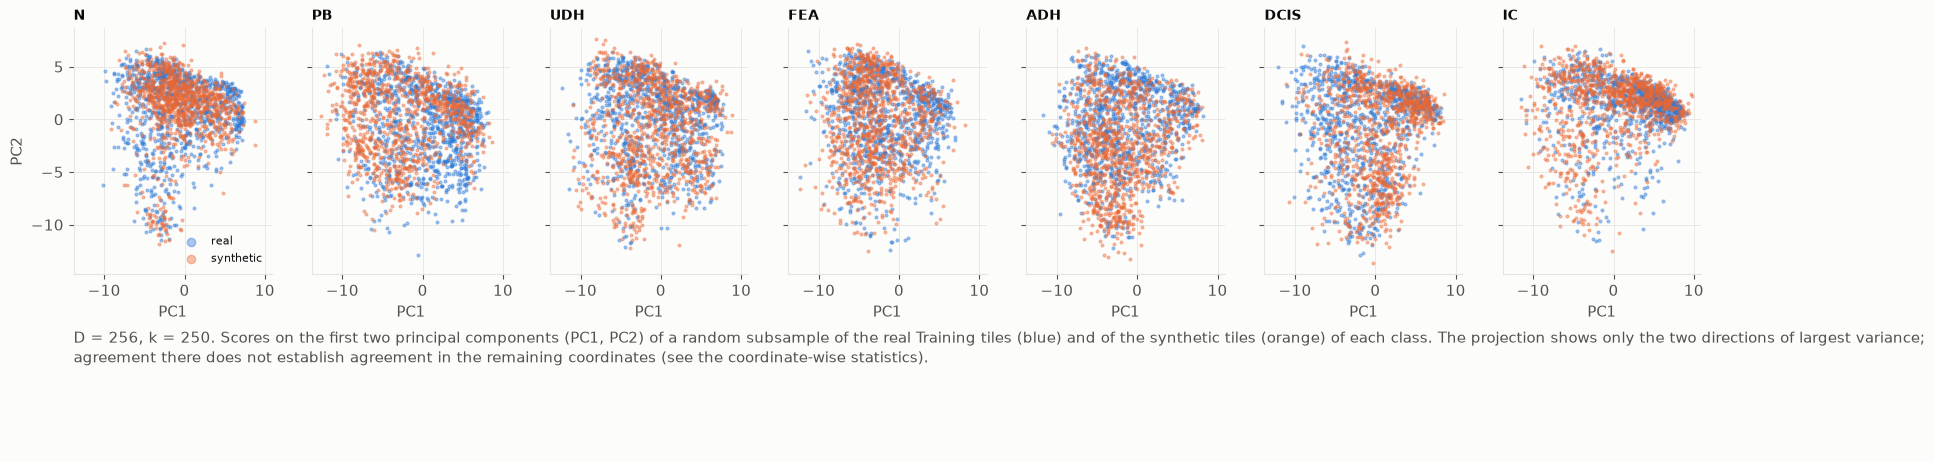

In [16]:
# STEP 1: Coordinate-wise statistics for every configuration
dist = pd.concat([r['distribution'].assign(pca_dim=dim, k=k) for (dim, k), r in results.items()], ignore_index=True)
_ = plot_distribution_stats(dist, classes)
display(dist[(dist['pca_dim'] == DIAGNOSTIC_CONFIG[0]) & (dist['k'] == DIAGNOSTIC_CONFIG[1])].round(3))

# STEP 2: Scores on the first two components
_ = plot_pc_scatter(res['scatter'], classes, title=f'D = {DIAGNOSTIC_CONFIG[0]}, k = {DIAGNOSTIC_CONFIG[1]}.')

### 8.6 Between-slide variance of the cluster means

For every cluster, the share of its variance that lies between slides is estimated from the per-slide cluster means of the real Training slides and, with the same estimator, from the cluster means of the first synthetic bags of the class (the cluster a tile was drawn for). A generator without per-bag offsets (`'gaussian'`, or `OFFSET_SCALE = 0`) has a synthetic share near zero, because the mean of the tiles of a cluster in a bag converges to the cluster mean; the hierarchical generator should reproduce the real share. Both are estimates from a limited number of slides and bags; clusters seen in few slides are less reliable and are shown separately in the second panel.


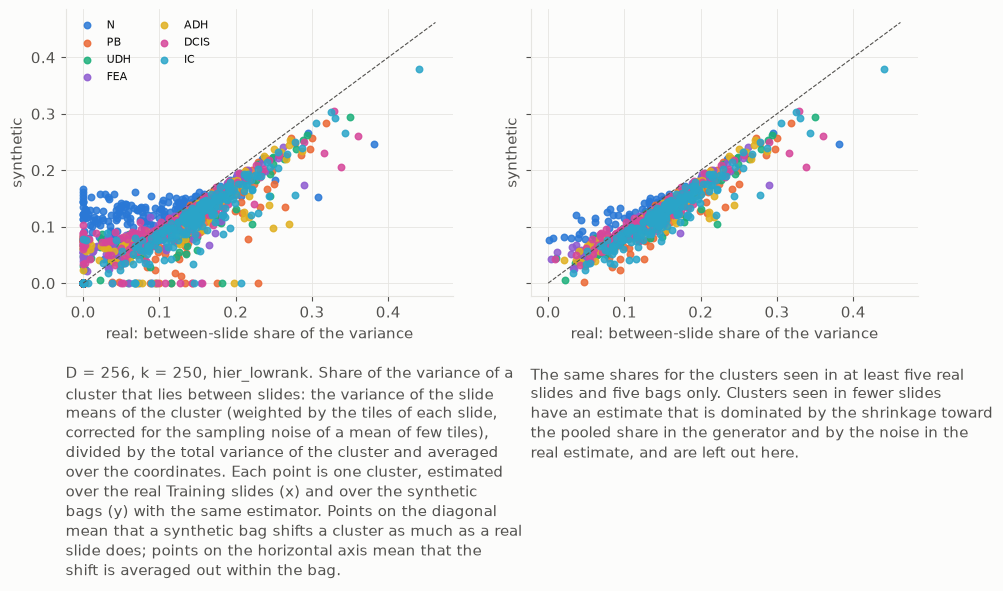

,real,synthetic
label,,
N,0.060,0.091
PB,0.135,0.105
UDH,0.101,0.086
FEA,0.084,0.079
ADH,0.085,0.076
DCIS,0.103,0.094
IC,0.142,0.112


In [17]:
# STEP 1: Between-slide share of the variance per cluster, real against synthetic (diagnostic configuration)
between = between_variance_table(stats[DIAGNOSTIC_CONFIG], res['bag_means'], MIN_CLUSTER_TILES, MIN_SLIDE_TILES)
_ = plot_between_variance(between, classes, title=f'D = {DIAGNOSTIC_CONFIG[0]}, k = {DIAGNOSTIC_CONFIG[1]}, {GENERATION_METHOD}.')

# STEP 2: Mean over the clusters of each class
display(between.groupby('label')[['real', 'synthetic']].mean().reindex(classes).round(3))


### 8.7 Can a classifier tell real from synthetic tiles?

A shallow gradient-boosting classifier is trained to separate real Training tiles from synthetic tiles of the same class and is scored by the area under the ROC curve on tiles of slides and bags that it has not seen (folds grouped by slide and by bag). The synthetic tiles come from 20 bags per class generated in memory for the diagnostic configuration. When the generation method is not `'gaussian'`, the independent-tile Gaussian with a diagonal covariance, estimated from the same statistics, is evaluated as a reference. A third reference separates two disjoint halves of the real slides and indicates the value reached by two real populations of this size. An AUC close to 0.5 means that no difference was found; the real tiles are the ones the generator was fitted on, so this is a fidelity check, not a test on new slides.


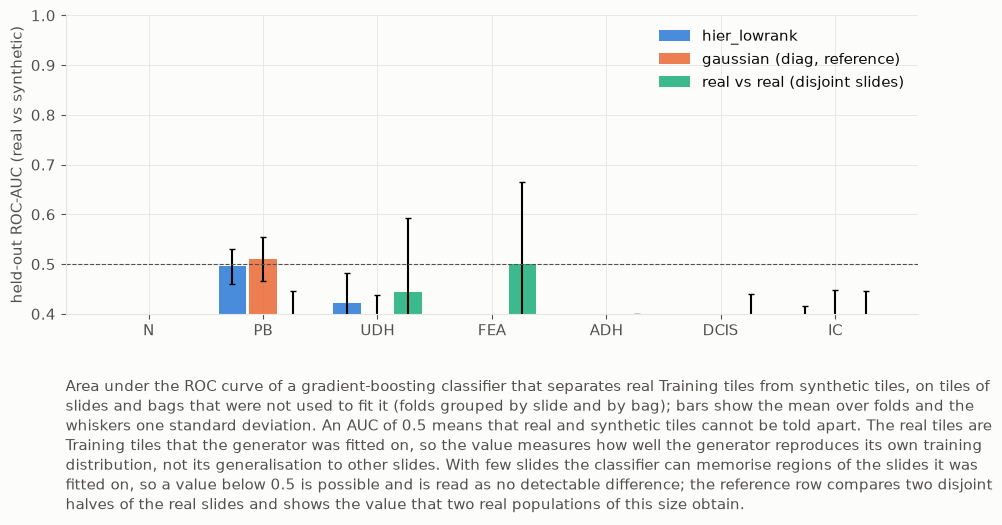

method,"gaussian (diag, reference)",hier_lowrank,real vs real (disjoint slides)
label,,,
N,0.188,0.202,0.295
PB,0.510,0.495,0.379
UDH,0.400,0.422,0.444
FEA,0.317,0.277,0.500
ADH,0.312,0.292,0.276
DCIS,0.341,0.310,0.361
IC,0.391,0.388,0.379


In [18]:
# STEP 1: Real against synthetic tiles per class: the chosen method, the Gaussian reference and two halves of the real slides
dim, k = DIAGNOSTIC_CONFIG
rng = np.random.default_rng([RANDOM_SEED, dim, k, 99])
rows = []
for label in classes:
    real, groups = real_diag[(dim, label)], real_groups[(dim, label)]
    compared = {GENERATION_METHOD: generators[DIAGNOSTIC_CONFIG][label]}
    if GENERATION_METHOD != 'gaussian':
        reference = build_generator('gaussian', covariance='diag', reg=COVARIANCE_REG, min_tiles=MIN_CLUSTER_TILES)
        compared['gaussian (diag, reference)'] = reference.fit(stats[DIAGNOSTIC_CONFIG][label], clusters[DIAGNOSTIC_CONFIG][label].cluster_centers_)
    for name, generator in compared.items():
        tiles, bags = sample_synthetic_tiles(generator, compositions[DIAGNOSTIC_CONFIG][label], rng, 20, 250, N_TEMPLATES_PER_WSI, TEMPLATE_CONCENTRATION, MAX_SYNTHETIC_TILES)
        rows.append({'label': label, 'method': name, **fidelity_auc(real, groups, tiles, bags, RANDOM_SEED)})
    half = np.isin(groups, np.unique(groups)[::2])
    rows.append({'label': label, 'method': 'real vs real (disjoint slides)', **fidelity_auc(real[half], groups[half], real[~half], groups[~half], RANDOM_SEED)})
fidelity = pd.DataFrame(rows)

# STEP 2: Figure and table
_ = plot_fidelity_auc(fidelity, classes)
display(fidelity.pivot_table(index='label', columns='method', values='auc').reindex(classes).round(3))


### 8.8 Lesion-share bags against real slides (`COMPOSITION_MODE = 'lesion_share'`)

The lesion share and the tile count of the synthetic ADH and DCIS bags are compared with those of the real Training slides (quantiles and the Kolmogorov-Smirnov distance between the two distributions; the synthetic share is that of the bag after it was assigned again to the nearest cluster centre, like the real slides). The correlation of the mean cluster proportions and of the entries of the cluster-by-cluster correlation matrices shows whether the average composition and the co-occurrence of clusters are reproduced. The last figure gives the held-out ROC-AUC of a regularised logistic regression that separates real slides from synthetic bags on the summary of a bag (its mean embedding and its cluster proportions); every slide and bag is one row, so the folds are grouped by slide or bag. The reference bars are the template-blending mode (the earlier behaviour, generated here with the same generator) and two disjoint halves of the real slides, which show the value that two real populations of this size obtain: an AUC near that value means that the bag summaries cannot be told apart from real ones, and values toward one mean that the bags have a structure that real slides do not. Only the summaries of the first bags of each class are available (section 7), and a class has few real slides, so the AUCs are noisy; no classification metric of a diagnostic model is reported here.

In [19]:
# STEP 1: Lesion share and tile count, real against synthetic (COMPOSITION_MODE = 'lesion_share' only)
if COMPOSITION_MODE == 'lesion_share':
    models = state['lesion'][DIAGNOSTIC_CONFIG]['models']
    wsis = results[DIAGNOSTIC_CONFIG]['wsis']
    display(lesion_share_comparison(models, wsis, classes).round(3))
    _ = plot_lesion_fit(models, wsis)

    # STEP 2: Cluster proportions of the real slides and of the synthetic bags
    real_props = {c: stats[DIAGNOSTIC_CONFIG][c]['counts'] / stats[DIAGNOSTIC_CONFIG][c]['counts'].sum(1, keepdims=True) for c in models}
    syn_counts = {c: np.stack(wsis.loc[wsis['WSI label'] == c, 'reassigned'].to_numpy()).astype(float) for c in models}
    display(proportion_correlation(real_props, {c: v / v.sum(1, keepdims=True) for c, v in syn_counts.items()}).round(3))

    # STEP 3: Can a bag-level classifier tell real from synthetic summaries? (lesion-share bags, template-blending bags, real halves)
    bag_auc = lesion_bag_auc(state, DIAGNOSTIC_CONFIG, PARAMS)
    _ = plot_fidelity_auc(bag_auc, list(models))
    display(bag_auc.pivot_table(index='label', columns='method', values='auc').round(3))
else:
    print("COMPOSITION_MODE = 'blend': nothing to compare.")

COMPOSITION_MODE = 'blend': nothing to compare.


## 9. Saving and reproducibility metadata

The bags were written in section 7. For each configuration, `metadata.json` (dimension, *k*, method, seed, bags per class, clustering, covariance type, regularisation and generator options (rank, offset scale, `MIN_SLIDES`, `MIN_SLIDE_TILES`, shrinkage, shared codebook), sampling, source split and a hash of the source slides, time stamp, library versions), `cluster_models.pt` (centres, cluster sizes and generator parameters, including the between-slide variance and the low-rank factors of the hierarchical generator) and `labels.csv` are stored next to them. The label sheet of all configurations, `labels/BRACS_synthetic.csv`, uses the columns of `BRACS.xlsx` plus the configuration and the tile counts. Existing files are not replaced unless `OVERWRITE` is set. In the lesion-share mode `lesion_share.csv`, the lesion rule and the lesion clusters (`metadata.json`) and the lesion-share model (`cluster_models.pt`) are added; with `MIN_CLUSTER_SLIDES > 0` the removed clusters are recorded; the key `generator_method` names the generator when the folder name carries a tag. With `PER_FOLD` the sheet of fold *k* is `labels/BRACS_synthetic_cv_fold_<k>.csv`.

In [20]:
# STEP 1: Metadata, cluster models and per-configuration labels, and the label sheet of the source
sheet = save_state(state, PARAMS, OVERWRITE)
if sheet is not None:
    display(sheet.groupby(['method', 'pca_dim', 'k', 'WSI label']).size().unstack().loc[:, classes])
else:
    print('SAVE_SYNTHETIC_EMBEDDINGS is False: nothing was written.')

WSI label                          N   PB  UDH  FEA  ADH  DCIS   IC
method              pca_dim k                                      
hier_lowrank_shared 256     100  500  500  500  500  500   500  500
                            150  500  500  500  500  500   500  500
                            250  500  500  500  500  500   500  500
                    512     100  500  500  500  500  500   500  500
                            150  500  500  500  500  500   500  500
                            250  500  500  500  500  500   500  500

## 10. Validation checks

One file of every configuration is read back and compared with its label-sheet row: shape `(n_tiles, D)`, dtype, finite values, label, set and the absence of real identifiers; the number of files per folder is compared with the configuration. No bag may be made of a single template when `N_TEMPLATES_PER_WSI > 1`.

In [21]:
# STEP 1: Reload one file per configuration
if SAVE_SYNTHETIC_EMBEDDINGS:
    sheet = pd.read_csv(SOURCE['labels_file'])
    for (dim, k), r in results.items():
        folder = r['folder']
        files = sorted(folder.glob('SYN_*.pt'))
        assert len(files) == N_SYNTHETIC_WSIS_PER_CLASS * len(classes), (folder, len(files))
        rows = sheet[(sheet['method'] == r['wsis']['method'].iloc[0]) & (sheet['pca_dim'] == dim) & (sheet['k'] == k)]
        assert len(rows) == len(files), (folder, len(rows), len(files))
        row = rows.iloc[len(rows) // 2]
        d = torch.load(folder / f"{row['WSI Filename']}.pt", weights_only=True)
        x = d['cls_features']
        assert x.shape == (row['n_tiles'], dim) and x.dtype == torch.float32 and torch.isfinite(x).all()
        assert d['label'] == row['WSI label'] and d['set'] == 'Synthetic' and d['patient'] == d['slide'] == row['WSI Filename']
        assert 'BRACS' not in d['slide']
        if N_TEMPLATES_PER_WSI > 1:
            assert (r['wsis']['max_template_weight'] < 1).all()
    print('All', len(results), 'configurations passed the checks.')

All 3 configurations passed the checks.


### 10.1 The other folds (`PER_FOLD`)

With `PER_FOLD = True` the same pipeline (selection, clustering, statistics, removal of sparse clusters, generator, lesion model, generation and saving) is run for every fold other than `DIAGNOSTIC_FOLD`, without the diagnostics. Each fold writes to `cv_fold_<k>/synthetic/<method>/pca_<D>/k_<K>/` and its own label sheet. The large arrays of a fold are released when it is finished. The table lists what was generated and which clusters were removed. Without `PER_FOLD` nothing is run.

In [22]:
# STEP 1: The remaining folds (PER_FOLD only), one after the other
if PER_FOLD:
    done = [run_source(source, PARAMS, OVERWRITE) for source in sources if source['fold'] != DIAGNOSTIC_FOLD]
    display(pd.DataFrame([{**{k: v for k, v in d.items() if k != 'pruned'}, 'pruned_configurations': sum(bool(v) for v in d['pruned'].values())} for d in done]))
else:
    print('PER_FOLD is False: nothing to run.')

[fold 1 D=256 N: sample] 0.1 s
[fold 1 D=256 PB: sample] 0.7 s
[fold 1 D=256 UDH: sample] 0.3 s
[fold 1 D=256 FEA: sample] 0.2 s
[fold 1 D=256 ADH: sample] 0.2 s
[fold 1 D=256 DCIS: sample] 0.2 s
[fold 1 D=256 IC: sample] 0.6 s
[fold 1 D=256: shared codebook k=[100, 150, 250]] 3.4 s
[fold 1 D=256 k=100: composition and statistics] 6.7 s
[fold 1 D=256 k=150: composition and statistics] 7.3 s
[fold 1 D=256 k=250: composition and statistics] 8.8 s
[fold 1: Gaussian parameters] 16.0 s
[fold 1 D=256 k=100: generation] 240.0 s
[fold 1 D=256 k=150: generation] 237.5 s
[fold 1 D=256 k=250: generation] 228.0 s
[fold 2 D=256 N: sample] 0.2 s
[fold 2 D=256 PB: sample] 0.6 s
[fold 2 D=256 UDH: sample] 0.3 s
[fold 2 D=256 FEA: sample] 0.2 s
[fold 2 D=256 ADH: sample] 0.3 s
[fold 2 D=256 DCIS: sample] 0.2 s
[fold 2 D=256 IC: sample] 0.7 s
[fold 2 D=256: shared codebook k=[100, 150, 250]] 3.6 s
[fold 2 D=256 k=100: composition and statistics] 6.9 s
[fold 2 D=256 k=150: composition and statistics] 7.7

,name,configurations,bags,sheet,pruned_configurations
0,fold 1,"[(256, 100), (256, 150), (256, 250)]",10500,21000,0
1,fold 2,"[(256, 100), (256, 150), (256, 250)]",10500,10500,0
2,fold 3,"[(256, 100), (256, 150), (256, 250)]",10500,10500,0
3,fold 4,"[(256, 100), (256, 150), (256, 250)]",10500,10500,0


## 11. Interpretation

To be written after the run on the workstation: the cluster balance per class and *k*, the agreement of tile counts and cluster proportions with the real templates (and the narrower spread caused by blending), the coordinate-wise agreement of the embeddings (standardised mean difference, standard-deviation ratio), the share of tiles that fall back into their generating cluster, the between-slide share of the variance of the clusters in real slides and in synthetic bags (section 8.6) and the held-out AUC of the classifier that separates real from synthetic tiles for the hierarchical and the independent-tile generator (section 8.7).
